# Phase I: How does the diabetes model behave?

**Research question:** Which diabetes-positive records does the model miss, and how does the pattern change when we change its decision threshold?

We treat Logistic Regression as a black box in this phase: use its predictions and probabilities, but do not inspect its coefficients or SHAP explanations yet. Every record gets an out-of-fold prediction from a model that was not trained on that record.

**Dataset:** Pima Indians Diabetes (OpenML data ID 37), 768 records. The dataset represents adult women of Pima heritage, so findings describe this dataset and should not be presented as a general clinical screening result.

**Data handling choice:** In this dataset, zero is used as a missing-value code for several measurements. We will count those values, replace zero with missing for glucose, blood pressure, skin thickness, insulin, and BMI, and let the model pipeline impute medians using training folds only. A zero pregnancy count remains valid.

# Step 1 — Pima Diabetes Dataset Preparation

**Purpose:** inspect the CSV and produce a concise data-quality summary before modeling.

The expected file is `diabetes.csv` in the same folder as this notebook. The CSV can use either Kaggle-style column names (`Pregnancies`, `Glucose`, …, `Outcome`) or OpenML-style names (`preg`, `plas`, …, `class`).

The notebook checks the number of records and input features, target labels, data types, missing values, duplicates, zero values, and negative values. It flags zero measurements that may represent missing data; it does not replace them. A zero pregnancy count is valid.

**Important limitation:** the Pima dataset contains 768 records from adult women of Pima heritage. Describe this dataset accurately and do not present it as representative of everyone or as a clinical diagnostic tool.

In [10]:
from pathlib import Path
import re
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value)

CSV_PATH = Path('diabetes.csv')
if not CSV_PATH.exists():
    raise FileNotFoundError(
        'diabetes.csv was not found. Download it, upload/copy it into the same folder as this notebook, and rerun.'
    )

raw = pd.read_csv(CSV_PATH)
print(f'Loaded: {CSV_PATH.resolve()}')
print(f'Rows: {raw.shape[0]} | Columns (including target): {raw.shape[1]}')
print('Original column names:', list(raw.columns))


Loaded: /drive/notebooks/diabetes.csv
Rows: 768 | Columns (including target): 9
Original column names: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


In [11]:
# Identify the outcome column and standardize the eight feature names.
def simplify(name):
    return re.sub(r'[^a-z0-9]', '', str(name).strip().lower())

TARGET_ALIASES = {'outcome', 'class', 'target', 'diabetes'}
target_candidates = [c for c in raw.columns if simplify(c) in TARGET_ALIASES]
if len(target_candidates) != 1:
    raise ValueError(
        f'Expected one target column named Outcome, class, target, or diabetes. Found: {target_candidates}'
    )
target_column = target_candidates[0]

ALIASES = {
    'preg': 'pregnancies', 'pregnancies': 'pregnancies',
    'plas': 'glucose', 'glucose': 'glucose',
    'pres': 'blood_pressure', 'bloodpressure': 'blood_pressure',
    'skin': 'skin_thickness', 'skinthickness': 'skin_thickness',
    'insu': 'insulin', 'insulin': 'insulin',
    'mass': 'bmi', 'bmi': 'bmi',
    'pedi': 'diabetes_pedigree', 'diabetespedigreefunction': 'diabetes_pedigree',
    'diabetespedigree': 'diabetes_pedigree',
    'age': 'age'
}
feature_columns = [c for c in raw.columns if c != target_column]
renamed = {c: ALIASES.get(simplify(c), simplify(c)) for c in feature_columns}
data = raw.rename(columns=renamed).copy()

EXPECTED_FEATURES = [
    'pregnancies', 'glucose', 'blood_pressure', 'skin_thickness',
    'insulin', 'bmi', 'diabetes_pedigree', 'age'
]
missing_features = [c for c in EXPECTED_FEATURES if c not in data.columns]
if missing_features:
    raise ValueError(f'Missing expected input features: {missing_features}')

# Keep a clean, clearly named table for inspection.
X = data[EXPECTED_FEATURES].apply(pd.to_numeric, errors='coerce')
y = raw[target_column].copy()
print(f'Outcome column: {target_column}')
print(f'Input features found: {len(EXPECTED_FEATURES)}')
print(f'Expected shape check: {"PASS" if len(raw) == 768 and len(EXPECTED_FEATURES) == 8 else "CHECK"}')


Outcome column: Outcome
Input features found: 8
Expected shape check: PASS


## 1. Inspect structure and completeness

Check that the file has the expected size, that the eight input columns are numeric, and that there are no unexpected missing cells or duplicate records.

In [12]:
structure = pd.DataFrame({
    'column': EXPECTED_FEATURES + [target_column],
    'role': ['input feature'] * len(EXPECTED_FEATURES) + ['outcome'],
    'data type': [str(X[c].dtype) for c in EXPECTED_FEATURES] + [str(y.dtype)],
    'missing values': [int(X[c].isna().sum()) for c in EXPECTED_FEATURES] + [int(y.isna().sum())]
})
display(structure)

quality_overview = pd.Series({
    'records': len(raw),
    'input features': len(EXPECTED_FEATURES),
    'outcome column': target_column,
    'missing input cells': int(X.isna().sum().sum()),
    'missing outcome labels': int(y.isna().sum()),
    'duplicate full rows': int(raw.duplicated().sum())
}, name='value')
display(quality_overview.to_frame())


,column,role,data type,missing values
0,pregnancies,input feature,int64,0
1,glucose,input feature,int64,0
2,blood_pressure,input feature,int64,0
3,skin_thickness,input feature,int64,0
4,insulin,input feature,int64,0
5,bmi,input feature,float64,0
6,diabetes_pedigree,input feature,float64,0
7,age,input feature,int64,0
8,Outcome,outcome,int64,0


,value
records,768
input features,8
outcome column,Outcome
missing input cells,0
missing outcome labels,0
duplicate full rows,0


## 2. Inspect outcome labels

This checks how many records belong to each outcome label. It is a description of the dataset, not a model-performance score.

,records,share
outcome,,
0,500,0.651
1,268,0.349


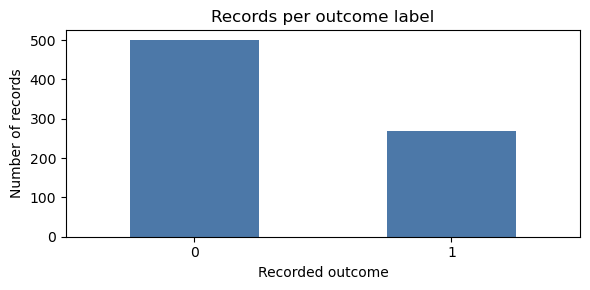

In [13]:
outcome_counts = y.value_counts(dropna=False).rename_axis('outcome').to_frame('records')
outcome_counts['share'] = (outcome_counts['records'] / len(y)).round(3)
display(outcome_counts)

ax = outcome_counts['records'].plot(kind='bar', figsize=(6, 3), color='#4C78A8')
ax.set_title('Records per outcome label')
ax.set_xlabel('Recorded outcome')
ax.set_ylabel('Number of records')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 3. Check zero and negative values

The dataset uses zero for some measurements that cannot realistically be zero. We flag these values as **potential missing-value codes** for the group to decide how to handle in Step 2. We do not change the data in this inspection notebook. A value of zero for pregnancies is valid.

,zero values,negative values,zero interpretation
pregnancies,111,0,valid value
glucose,5,0,review: zero may encode missing
blood_pressure,35,0,review: zero may encode missing
skin_thickness,227,0,review: zero may encode missing
insulin,374,0,review: zero may encode missing
bmi,11,0,review: zero may encode missing
diabetes_pedigree,0,0,review if zero appears
age,0,0,review if zero appears


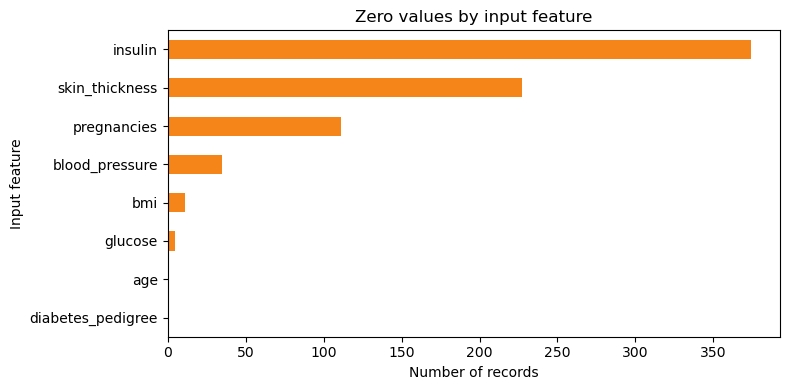

In [14]:
zero_counts = X.eq(0).sum().rename('zero values')
negative_counts = X.lt(0).sum().rename('negative values')

potential_missing_zero_features = [
    'glucose', 'blood_pressure', 'skin_thickness', 'insulin', 'bmi'
]
zero_audit = pd.concat([zero_counts, negative_counts], axis=1).fillna(0).astype(int)
zero_audit['zero interpretation'] = [
    'valid value' if feature == 'pregnancies' else
    'review: zero may encode missing' if feature in potential_missing_zero_features else
    'review if zero appears'
    for feature in zero_audit.index
]
display(zero_audit)

ax = zero_counts.sort_values().plot(kind='barh', figsize=(8, 4), color='#F58518')
ax.set_title('Zero values by input feature')
ax.set_xlabel('Number of records')
ax.set_ylabel('Input feature')
plt.tight_layout()
plt.show()


## 4. Review feature ranges

This table reports minimum, median, maximum, and negative-value counts. Use it to spot values that need a closer look. Do not label a value medically impossible without checking the dataset documentation or agreeing on a rule with the group.

In [15]:
range_summary = X.agg(['count', 'min', 'median', 'max']).T
range_summary['negative values'] = negative_counts
range_summary['zero values'] = zero_counts
display(range_summary)


,count,min,median,max,negative values,zero values
pregnancies,768.0,0.000,3.0000,17.00,0,111
glucose,768.0,0.000,117.0000,199.00,0,5
blood_pressure,768.0,0.000,72.0000,122.00,0,35
skin_thickness,768.0,0.000,23.0000,99.00,0,227
insulin,768.0,0.000,30.5000,846.00,0,374
bmi,768.0,0.000,32.0000,67.10,0,11
diabetes_pedigree,768.0,0.078,0.3725,2.42,0,0
age,768.0,21.000,29.0000,81.00,0,0


## 5. Create the Step 1 data-quality summary

Run this cell to save a short Markdown report beside the notebook. Review the zero-value treatment with the group before Step 2; the notebook only flags possible missing-value codes.

In [ ]:
flagged_zeros = zero_counts[zero_counts.index.isin(potential_missing_zero_features) & (zero_counts > 0)]
if len(flagged_zeros):
    zero_text = ', '.join(f'{name}: {int(count)}' for name, count in flagged_zeros.items())
else:
    zero_text = 'No zero values found in the selected measurement features.'

negative_text = ', '.join(f'{name}: {int(count)}' for name, count in negative_counts.items() if count > 0)
if not negative_text:
    negative_text = 'No negative values found.'

outcome_markdown = '| outcome | records | share |\n|---|---:|---:|\n' + '\n'.join(
    f'| {index} | {int(row.records)} | {row.share:.3f} |'
    for index, row in outcome_counts.iterrows()
)

summary = f'''# Step 1 Data Quality Summary

## Dataset
- File: `{CSV_PATH.name}`
- Records: {len(raw)}
- Input features: {len(EXPECTED_FEATURES)} ({', '.join(EXPECTED_FEATURES)})
- Outcome column: `{target_column}`
- Duplicate full rows: {int(raw.duplicated().sum())}
- Missing input cells: {int(X.isna().sum().sum())}
- Missing outcome labels: {int(y.isna().sum())}

## Outcome counts
{outcome_markdown}

## Values to review
- Zero values that may represent missing measurements: {zero_text}
- Negative values: {negative_text}
- Zero pregnancies are treated as valid; the other flagged zeros have not been changed in this notebook.

## Limitations
The Pima dataset contains 768 records from adult women of Pima heritage. Findings should be described as patterns in this dataset, not as general clinical guidance.

## Next step
In Step 2, agree with the group which zero codes to treat as missing and fit imputation/scaling using training data only.
'''

summary_path = Path('Step1_data_quality_summary.md')
summary_path.write_text(summary, encoding='utf-8')
print(f'Saved summary to: {summary_path.resolve()}')
print(summary)


Saved summary to: /drive/notebooks/Step1_data_quality_summary.md
# Step 1 Data Quality Summary

## Dataset
- File: `diabetes.csv`
- Records: 768
- Input features: 8 (pregnancies, glucose, blood_pressure, skin_thickness, insulin, bmi, diabetes_pedigree, age)
- Outcome column: `Outcome`
- Duplicate full rows: 0
- Missing input cells: 0
- Missing outcome labels: 0

## Outcome counts
| outcome | records | share |
|---|---:|---:|
| 0 | 500 | 0.651 |
| 1 | 268 | 0.349 |

## Values to review
- Zero values that may represent missing measurements: glucose: 5, blood_pressure: 35, skin_thickness: 227, insulin: 374, bmi: 11
- Negative values: No negative values found.
- Zero pregnancies are treated as valid; the other flagged zeros have not been changed in this notebook.

## Limitations
The Pima dataset contains 768 records from adult women of Pima heritage. Findings should be described as patterns in this dataset, not as general clinical guidance.

## Next step
In Step 2, agree with the group whi